<a href="https://colab.research.google.com/github/Vadim-SM/Lab1../blob/main/notebooks/PR02_Musienko_Vadim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Практична робота 2
## Дослідницький аналіз і підготовка даних
**Дисципліна:** Розпізнавання образів і машинне навчання
**Студент:** [Мусієнко Вадим]
**Група:** [ІН-42/1]
**Дата виконання:** 22 жовтня 2026 року

### Мета роботи
Навчитися аналізувати якість табличних даних, виявляти та виправляти пропуски, дублікати, неправильні типи й аномальні значення, кодувати категоріальні ознаки та формувати навчальну і тестову вибірки.


## 1. Підключення бібліотек
Підключаються бібліотеки для роботи з таблицями, числовими даними, візуалізацією, збереженням метаданих і формуванням train/test-вибірок.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from IPython.display import display

In [2]:
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.16
NumPy: 2.1.3
pandas: 2.2.3
scikit-learn: 1.6.1


## 2. Підключення Google Drive
Google Drive використовується для читання початкових даних і збереження результатів очищення.



In [3]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/pattern-recognition-practice")
DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
REPORTS_DIR = PROJECT_DIR / "reports"

SOURCE_PATH = DATA_DIR / "iris.csv"
DIRTY_PATH = DATA_DIR / "iris_dirty.csv"
CLEANED_PATH = PROCESSED_DIR / "iris_cleaned.csv"
X_TRAIN_PATH = PROCESSED_DIR / "X_train.csv"
X_TEST_PATH = PROCESSED_DIR / "X_test.csv"
Y_TRAIN_PATH = PROCESSED_DIR / "y_train.csv"
Y_TEST_PATH = PROCESSED_DIR / "y_test.csv"
SUMMARY_PATH = REPORTS_DIR / "preprocessing_summary.csv"
CLASS_MAPPING_PATH = REPORTS_DIR / "class_mapping.json"

DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Папка проєкту:", PROJECT_DIR)
print("Папка початкових даних:", DATA_DIR)
print("Папка підготовлених даних:", PROCESSED_DIR)
print("Папка звітів:", REPORTS_DIR)

Mounted at /content/drive
Папка проєкту: /content/drive/MyDrive/pattern-recognition-practice
Папка початкових даних: /content/drive/MyDrive/pattern-recognition-practice/data
Папка підготовлених даних: /content/drive/MyDrive/pattern-recognition-practice/data/processed
Папка звітів: /content/drive/MyDrive/pattern-recognition-practice/reports


## 3. Завантаження початкового набору Iris
Спочатку перевіряється наявність файла `iris.csv`, створеного у практичній роботі 1. Якщо файл відсутній, він створюється повторно.

In [4]:
if SOURCE_PATH.exists():
    source_df = pd.read_csv(SOURCE_PATH)
    print("Початковий файл завантажено з Google Drive.")
else:
    print("Файл iris.csv не знайдено. Створюємо його повторно.")
    iris = load_iris(as_frame=True)
    source_df = iris.frame.copy()
    source_df["species"] = source_df["target"].map(
        {
            0: "setosa",
            1: "versicolor",
            2: "virginica"
        }
    )
    source_df = source_df.drop(columns=["target"])
    source_df = source_df.rename(
        columns={
            "sepal length (cm)": "sepal_length_cm",
            "sepal width (cm)": "sepal_width_cm",
            "petal length (cm)": "petal_length_cm",
            "petal width (cm)": "petal_width_cm"
        }
    )
    source_df.to_csv(SOURCE_PATH, index=False)
    print("Файл iris.csv створено:", SOURCE_PATH)

display(source_df.head())
print("Розмір початкової таблиці:", source_df.shape)

Початковий файл завантажено з Google Drive.


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Розмір початкової таблиці: (150, 5)


## 4. Створення набору з контрольованими проблемами
Для навчальних цілей до початкового набору додаються типові проблеми, які можуть виникати під час збирання реальних даних[cite: 4].

In [5]:
rng = np.random.default_rng(42)
dirty_df = source_df.copy()

# Додаємо категоріальну ознаку, що імітує пристрій вимірювання.
dirty_df["measurement_device"] = rng.choice(
    ["device_a", "device_b", "device_c"],
    size=len(dirty_df),
    p=[0.40, 0.35, 0.25]
)

# Додаємо пропуски в різні стовпці.
missing_plan = {
    "sepal_length_cm": 4,
    "sepal_width_cm": 5,
    "petal_length_cm": 4,
    "petal_width_cm": 5,
    "measurement_device": 4,
    "species": 2
}

for column, amount in missing_plan.items():
    selected_indices = rng.choice(
        dirty_df.index,
        size=amount,
        replace=False
    )
    dirty_df.loc[selected_indices, column] = np.nan

# Перетворюємо один числовий стовпець на object, щоб до нього можна було додати текстові значення.
dirty_df["sepal_length_cm"] = dirty_df["sepal_length_cm"].astype("object")

# Додаємо записи з комою, пробілами та некоректним текстом.
dirty_df.loc[3, "sepal_length_cm"] = "5,1"
dirty_df.loc[25, "sepal_length_cm"] = "unknown"
dirty_df.loc[47, "sepal_length_cm"] = " 6.3 "

# Додаємо неузгоджені варіанти назв пристроїв.
dirty_df.loc[7, "measurement_device"] = " Device_A "
dirty_df.loc[19, "measurement_device"] = "DEVICE_B"
dirty_df.loc[33, "measurement_device"] = "device c"

# Додаємо явно некоректні та надзвичайні значення.
dirty_df.loc[10, "petal_length_cm"] = -1.0
dirty_df.loc[55, "sepal_width_cm"] = 18.0
dirty_df.loc[120, "petal_width_cm"] = 9.5

# Додаємо повні дублікати.
duplicate_rows = dirty_df.iloc[[6, 27, 50, 88]].copy()
dirty_df = pd.concat(
    [dirty_df, duplicate_rows],
    ignore_index=True
)

dirty_df.to_csv(DIRTY_PATH, index=False)
print("Пошкоджений набір створено:")
print(DIRTY_PATH)
print("Розмір:", dirty_df.shape)

Пошкоджений набір створено:
/content/drive/MyDrive/pattern-recognition-practice/data/iris_dirty.csv
Розмір: (154, 6)


In [6]:
raw_df = pd.read_csv(DIRTY_PATH)
display(raw_df.head())
print("Розмір таблиці:", raw_df.shape)

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
0,5.1,3.5,1.4,0.2,setosa,device_c
1,NaN,3.0,1.4,0.2,setosa,device_b
2,4.7,3.2,1.3,0.2,setosa,device_c
3,"5,1",3.1,1.5,0.2,setosa,device_b
4,5.0,3.6,1.4,0.2,setosa,device_a


Розмір таблиці: (154, 6)


## 5. Початковий аудит якості даних
На цьому етапі дані не виправляються. Спочатку необхідно зібрати інформацію про всі виявлені проблеми[cite: 4].

In [7]:
display(raw_df.head(10))
display(raw_df.tail(10))

print("\n--- Інформація про таблицю ---")
raw_df.info()

print("\n--- Зведена таблиця якості ---")
quality_report = pd.DataFrame(
    {
        "data_type": raw_df.dtypes.astype(str),
        "missing_count": raw_df.isna().sum(),
        "missing_percent": (
            raw_df.isna().mean().mul(100).round(2)
        ),
        "unique_count": raw_df.nunique(dropna=True)
    }
)
display(quality_report)

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
0,5.1,3.5,1.4,0.2,setosa,device_c
1,NaN,3.0,1.4,0.2,setosa,device_b
2,4.7,3.2,1.3,0.2,setosa,device_c
3,"5,1",3.1,1.5,0.2,setosa,device_b
4,5.0,3.6,1.4,0.2,setosa,device_a
5,5.4,3.9,1.7,NaN,setosa,device_c
6,4.6,3.4,1.4,0.3,setosa,device_c
7,5.0,3.4,1.5,0.2,setosa,Device_A
8,4.4,2.9,1.4,0.2,setosa,device_a
9,4.9,3.1,1.5,0.1,setosa,device_b


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
144,6.7,3.3,5.7,2.5,virginica,device_b
145,6.7,3.0,5.2,2.3,virginica,device_a
146,6.3,2.5,5.0,1.9,virginica,device_a
147,6.5,3.0,NaN,2.0,virginica,device_b
148,6.2,3.4,5.4,2.3,virginica,device_b
149,5.9,3.0,5.1,1.8,virginica,device_a
150,4.6,3.4,1.4,0.3,setosa,device_c
151,5.2,3.5,1.5,0.2,setosa,device_a
152,7.0,3.2,4.7,1.4,versicolor,device_a
153,5.6,3.0,4.1,1.3,versicolor,device_a



--- Інформація про таблицю ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 154 entries, 0 to 153
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   sepal_length_cm     150 non-null    object 
 1   sepal_width_cm      149 non-null    float64
 2   petal_length_cm     150 non-null    float64
 3   petal_width_cm      149 non-null    float64
 4   species             152 non-null    object 
 5   measurement_device  150 non-null    object 
dtypes: float64(3), object(3)
memory usage: 7.3+ KB

--- Зведена таблиця якості ---


,data_type,missing_count,missing_percent,unique_count
sepal_length_cm,object,4,2.60,38
sepal_width_cm,float64,5,3.25,24
petal_length_cm,float64,4,2.60,43
petal_width_cm,float64,5,3.25,23
species,object,2,1.30,3
measurement_device,object,4,2.60,6


**Відповіді на контрольні запитання аудиту якості (п. 9.3):**
1. **Які стовпці містять пропуски?** Пропуски містять усі стовпці: `sepal_length_cm`, `sepal_width_cm`, `petal_length_cm`, `petal_width_cm`, `measurement_device` та цільова змінна `species`[cite: 4].
2. **Який стовпець має неправильний тип?** Стовпець `sepal_length_cm` має тип `object` (текстовий) замість числового, через наявність текстових вставок та ком[cite: 4].
3. **Скільки унікальних значень має цільова змінна?** 3 унікальні значення (`setosa`, `versicolor`, `virginica`)[cite: 4].
4. **Скільки унікальних значень має категоріальна ознака?** Більше ніж 3 (через розбіжності у написанні)[cite: 4].
5. **Чому кількість варіантів measurement_device більша за три?** Через неузгоджені варіанти запису категорій (регістрові розбіжності та зайві пробіли, наприклад `" Device_A "`, `"DEVICE_B"`, `"device c"`)[cite: 4].

In [ ]:
## 6. Очищення даних та виправлення типів
На цьому етапі усуваються виявлені проблеми: видаляються дублікати та рядки без цільової змінної, виправляються типи даних, стандартизуються категорії та обробляються аномалії.

In [8]:
# Створюємо копію для очищення
df_clean = raw_df.copy()

# 1. Видалення повних дублікатів
initial_rows = len(df_clean)
df_clean = df_clean.drop_duplicates()
print(f"Видалено дублікатів: {initial_rows - len(df_clean)}")

# 2. Видалення об'єктів без відомого значення цільової змінної (species)
df_clean = df_clean.dropna(subset=["species"])
print(f"Розмір після видалення рядків без species: {df_clean.shape}")

# 3. Виправлення типу числового стовпця sepal_length_cm (перетворення тексту/ком на числа)
# Замінюємо кому на крапку, якщо вона є в текстових значеннях
df_clean["sepal_length_cm"] = (
    df_clean["sepal_length_cm"]
    .astype(str)
    .str.replace(",", ".", regex=False)
)
df_clean["sepal_length_cm"] = pd.to_numeric(
    df_clean["sepal_length_cm"], errors="coerce"
)
print("Тип sepal_length_cm після конвертації:", df_clean["sepal_length_cm"].dtype)

# 4. Стандартизація назв категорій у measurement_device
df_clean["measurement_device"] = (
    df_clean["measurement_device"]
    .astype(str)
    .str.lower()
    .str.strip()
)
# Виправляємо випадки на кшталт 'device c' на 'device_c' якщо потрібно або залишаємо стандартизованими
df_clean["measurement_device"] = df_clean["measurement_device"].replace({
    "device c": "device_c"
})

Видалено дублікатів: 4
Розмір після видалення рядків без species: (148, 6)
Тип sepal_length_cm після конвертації: float64


In [9]:
# Фізично неможливі значення (наприклад, довжина/ширина <= 0 або нереально великі) заносимо як пропуски (NaN)
df_clean.loc[df_clean["petal_length_cm"] <= 0, "petal_length_cm"] = np.nan
df_clean.loc[df_clean["sepal_width_cm"] > 15, "sepal_width_cm"] = np.nan
df_clean.loc[df_clean["petal_width_cm"] > 8, "petal_width_cm"] = np.nan

print("Кількість пропусків після переведення аномалій у NaN:")
print(df_clean.isna().sum())

Кількість пропусків після переведення аномалій у NaN:
sepal_length_cm       5
sepal_width_cm        6
petal_length_cm       5
petal_width_cm        6
species               0
measurement_device    0
dtype: int64


In [10]:
# Заповнення числових ознак медіаною
numeric_cols = [
    "sepal_length_cm",
    "sepal_width_cm",
    "petal_length_cm",
    "petal_width_cm"
]

for col in numeric_cols:
    median_val = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_val)

# Заповнення пропусків у категоріальній ознаці модою
mode_val = df_clean["measurement_device"].mode()[0]
df_clean["measurement_device"] = df_clean["measurement_device"].fillna(mode_val)

print("Загальна кількість пропусків після заповнення:", df_clean.isna().sum().sum())

Загальна кількість пропусків після заповнення: 0


In [11]:
df_clean.to_csv(CLEANED_PATH, index=False)
print("Очищений набір збережено у файл:", CLEANED_PATH)
print("Фінальний розмір очищеної таблиці:", df_clean.shape)

Очищений набір збережено у файл: /content/drive/MyDrive/pattern-recognition-practice/data/processed/iris_cleaned.csv
Фінальний розмір очищеної таблиці: (148, 6)


## 7. Кодування ознак та формування вибірок (Train/Test)
На цьому етапі категоріальні змінні перетворюються на числові за допомогою кодування, після чого набір даних розділяється на матрицю ознак `X`, цільову змінну `y` та формуються навчальна і тестова вибірки.

In [12]:
# Кодування категоріальної ознаки measurement_device (One-Hot Encoding)
df_encoded = pd.get_dummies(df_clean, columns=["measurement_device"], drop_first=True, dtype=int)

# Словник для кодування цільової змінної (species)
class_mapping = {
    "setosa": 0,
    "versicolor": 1,
    "virginica": 2
}

# Зберігаємо словник у JSON-звіт
with open(CLASS_MAPPING_PATH, "w", encoding="utf-8") as f:
    json.dump(class_mapping, f, ensure_ascii=False, indent=4)

df_encoded["species_encoded"] = df_encoded["species"].map(class_mapping)

# Розділення на матрицю ознак X та цільову змінну y
X = df_encoded.drop(columns=["species", "species_encoded"])
y = df_encoded["species_encoded"]

print("Розмір матриці ознак X:", X.shape)
print("Розмір цільової змінної y:", y.shape)

Розмір матриці ознак X: (148, 7)
Розмір цільової змінної y: (148,)


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Розмір X_train:", X_train.shape)
print("Розмір X_test:", X_test.shape)
print("Розмір y_train:", y_train.shape)
print("Розмір y_test:", y_test.shape)

Розмір X_train: (118, 7)
Розмір X_test: (30, 7)
Розмір y_train: (118,)
Розмір y_test: (30,)


In [14]:
X_train.to_csv(X_TRAIN_PATH, index=False)
X_test.to_csv(X_TEST_PATH, index=False)
y_train.to_csv(Y_TRAIN_PATH, index=False)
y_test.to_csv(Y_TEST_PATH, index=False)

print("Усі навчальні та тестові вибірки успішно збережено в папку processed!")

Усі навчальні та тестові вибірки успішно збережено в папку processed!


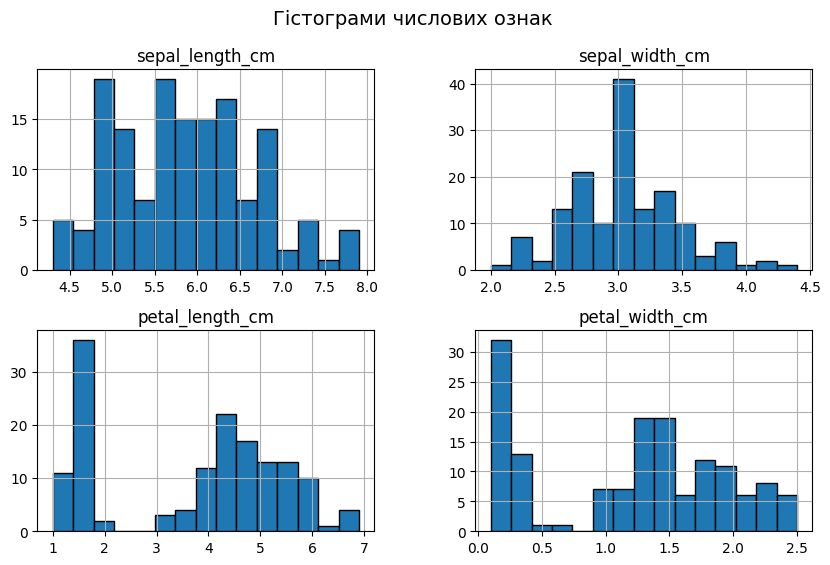

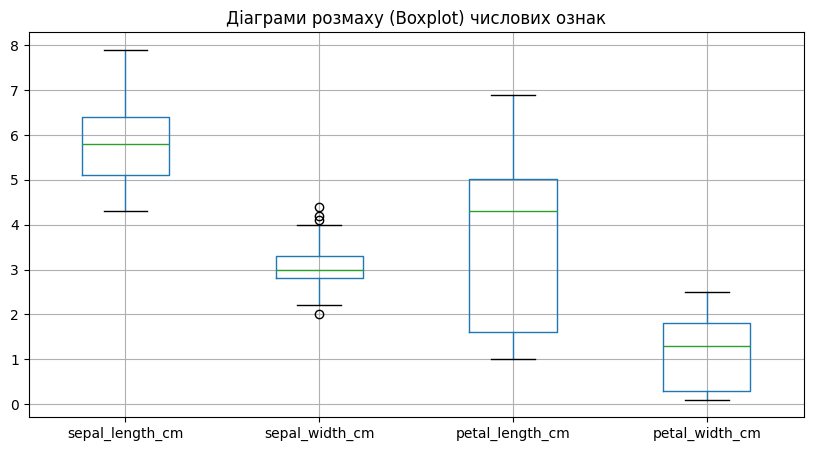

In [15]:
import matplotlib.pyplot as plt

# 17. Гістограми числових ознак
df_clean[numeric_cols].hist(bins=15, figsize=(10, 6), edgecolor='black')
plt.suptitle("Гістограми числових ознак", fontsize=14)
plt.show()

# 18. Діаграми розмаху (Boxplot) для виявлення аномалій
plt.figure(figsize=(10, 5))
df_clean[numeric_cols].boxplot()
plt.title("Діаграми розмаху (Boxplot) числових ознак")
plt.show()

In [16]:
# 19. Розподіл класів цільової змінної
class_counts = df_clean["species"].value_counts()
print("Розподіл класів у цільовій змінній:")
display(class_counts)

# 25. Таблиця порівняння класів (розподіл у train та test)
train_comparison = y_train.value_counts().rename("Train count")
test_comparison = y_test.value_counts().rename("Test count")
comparison_df = pd.concat([train_comparison, test_comparison], axis=1)
comparison_df["Train %"] = (comparison_df["Train count"] / len(y_train) * 100).round(2)
comparison_df["Test %"] = (comparison_df["Test count"] / len(y_test) * 100).round(2)
print("\nПорівняння розподілу класів у Train / Test:")
display(comparison_df)

Розподіл класів у цільовій змінній:


,count
species,
setosa,50
versicolor,49
virginica,49



Порівняння розподілу класів у Train / Test:


,Train count,Test count,Train %,Test %
species_encoded,,,,
0,40,10,33.90,33.33
1,39,10,33.05,33.33
2,39,10,33.05,33.33


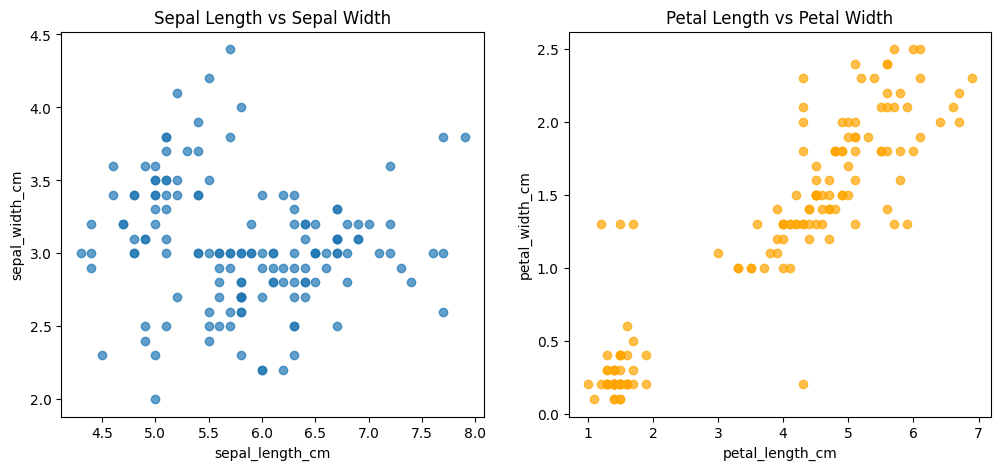

Матриця кореляцій:


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
sepal_length_cm,1.000000,-0.104824,0.818996,0.760174
sepal_width_cm,-0.104824,1.000000,-0.402899,-0.354642
petal_length_cm,0.818996,-0.402899,1.000000,0.916701
petal_width_cm,0.760174,-0.354642,0.916701,1.000000


In [17]:
# 20. Діаграми залежностей ( Scatter plots )
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(df_clean["sepal_length_cm"], df_clean["sepal_width_cm"], alpha=0.7)
axes[0].set_title("Sepal Length vs Sepal Width")
axes[0].set_xlabel("sepal_length_cm")
axes[0].set_ylabel("sepal_width_cm")

axes[1].scatter(df_clean["petal_length_cm"], df_clean["petal_width_cm"], color="orange", alpha=0.7)
axes[1].set_title("Petal Length vs Petal Width")
axes[1].set_xlabel("petal_length_cm")
axes[1].set_ylabel("petal_width_cm")
plt.show()

# 21. Матриця кореляцій числових ознак
corr_matrix = df_clean[numeric_cols].corr()
print("Матриця кореляцій:")
display(corr_matrix)

In [18]:
# 26. Автоматичні перевірки (asserts)
assert df_clean.isna().sum().sum() == 0, "Увага: залишилися пропущені значення!"
assert len(X_train) == len(y_train), "Розміри train-вибірки не збігаються!"
assert len(X_test) == len(y_test), "Розміри test-вибірки не збігаються!"
print("Успіх: Усі автоматичні перевірки (asserts) пройдено успішно!")

Успіх: Усі автоматичні перевірки (asserts) пройдено успішно!
